# **Text As Data**

### Acquiring Dataset

In [1]:
import pandas as pd

In [3]:
# Put Fake.csv and True.csv inside a "data" folder next to this notebook
df_fake = pd.read_csv("data/Fake.csv")
df_true = pd.read_csv("data/True.csv")

<>:2: SyntaxWarning: invalid escape sequence '\F'
<>:2: SyntaxWarning: invalid escape sequence '\F'
C:\Users\somys\AppData\Local\Temp\ipykernel_40548\2572599002.py:2: SyntaxWarning: invalid escape sequence '\F'
  df_true = pd.read_csv("C:\\Users\\somys\\Downloads\\data\\fake-and-real-news-dataset\Fake.csv")


In [4]:
df_fake["label"] = "fake"
df_true["label"] = "true"
data = pd.concat([df_fake, df_true]).reset_index(drop=True)

In [5]:
data.sample(7)

,title,text,subject,date,label
21182,Myanmar army drops charges against six journal...,YANGON (Reuters) - Myanmar s military on Frida...,worldnews,"September 1, 2017",fake
29118,Republicans Had Total Control Of This State A...,Bobby Jindal abandoned his home state of Louis...,News,"March 4, 2016",true
21364,Qatar enacts law to protect foreign domestic w...,DOHA (Reuters) - Qatar s ruler has introduced ...,worldnews,"August 24, 2017",fake
40829,ARMED BLACK PANTHERS March In Milwaukee: “Free...,,left-news,"Dec 21, 2016",true
36914,BREAKING: GUN USED BY 5 TIME DEPORTED ILLEGAL ...,Just another interesting discovery in a story ...,politics,"Jul 8, 2015",true
40282,CHER HUMILIATES Democrats Over Childish Neil G...,"DEMS,The Merrick Garland SHIP HAS SAILED Let ...",left-news,"Apr 4, 2017",true
33745,COMEDIAN TIM ALLEN On Hollywood Hypocrites: Th...,https://youtu.be/0J4xPRYbsLU,politics,"Nov 22, 2016",true


In [6]:
data.shape

(44898, 5)

### Drop Unnecessary Columns

In [7]:
data.drop(columns=[ "subject", "date"], inplace=True)

In [8]:
data.sample(4)

,title,text,label
40111,"RADICAL “TOLERANT” FEMALE Black Bloc, Antifa L...",DC Antifa Leader Moved to Turkey with Man She ...,true
16386,"In Mexican slum, a decades-long wait for quake...",MEXICO CITY (Reuters) - I first visited Camp N...,fake
12075,Palestinian protesters set fire to placards of...,"BETHLEHEM, West Bank (Reuters) - A small group...",fake
43286,https://fedup.wpengine.com/wp-content/uploads/...,https://fedup.wpengine.com/wp-content/uploads/...,true


In [9]:
data.duplicated().sum()

5793

In [10]:
data.drop_duplicates(inplace=True)

In [11]:
data.shape

(39105, 3)

Making two copies. one for ML models and the other for Sequence models

In [12]:
data1 = data.copy()
data2 = data.copy()

### Data cleaning and preprocessing

In [13]:
import re
import numpy as np
import nltk

from nltk.stem.snowball import SnowballStemmer
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [14]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')


# Init the Wordnet Lemmatizer
lemmatizer = WordNetLemmatizer()
stemmer = SnowballStemmer("english")
stop_words = set(stopwords.words("english"))

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\somys\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\somys\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\somys\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


### Function For ML Models

In [15]:
def clean_text(text,stem,lem):
    # remove special characters and numbers
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    # remove unnecessary spaces
    text = re.sub(r"\s+", " ", text)
    # tokenize the text
    word_tokens = word_tokenize(text)
    # case folding
    word_tokens = [word.lower() for word in word_tokens]
    # remove stop words
    filtered_text = [word for word in word_tokens if word not in stop_words]
    # lemmatization and/or stemming
    if lem==True:
        filtered_text = [lemmatizer.lemmatize(word) for word in filtered_text]
    if stem==True:
        filtered_text = [stemmer.stem(word) for word in filtered_text]

    text_clean = " ".join(filtered_text)
    return text_clean

In [16]:
#example usage
clean_text("This is a Sample text    with Numbers 123 and Special Characters !@#.", stem=False, lem=True)

'sample text number special character'

In [17]:
data1["title"] = data1["title"].apply(lambda x: clean_text(x, stem=False, lem=True))
data1["text"] = data1["text"].apply(lambda x: clean_text(x, stem=False, lem=True))

In [18]:
data1.sample(4)

,title,text,label
26303,wv republican ag spokeswoman busted appearing ...,know adorable white supremacist christian atte...,true
36063,breaking obama administration expand number re...,basically obama administration making easier c...,true
35079,breaking yr old man arrested trying steal offi...,another deranged leftist registered democrat m...,true
35997,actor rob lowe blast greedy socialist bernie s...,always fun hollywood show conservative side ro...,true


### Visualization for Analysis

In [ ]:
! pip install wordcloud

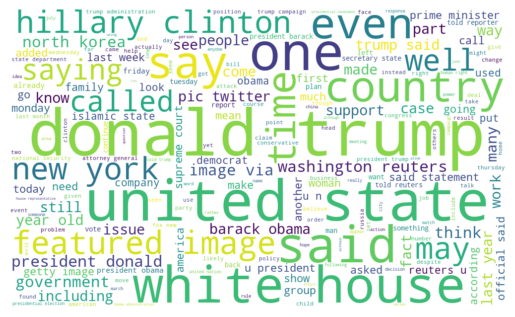

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

text = " ".join(data1['text'])
wc = WordCloud(width=1000, height=600, background_color='white').generate(text)
plt.imshow(wc, interpolation='bilinear')
plt.axis("off")
plt.show()


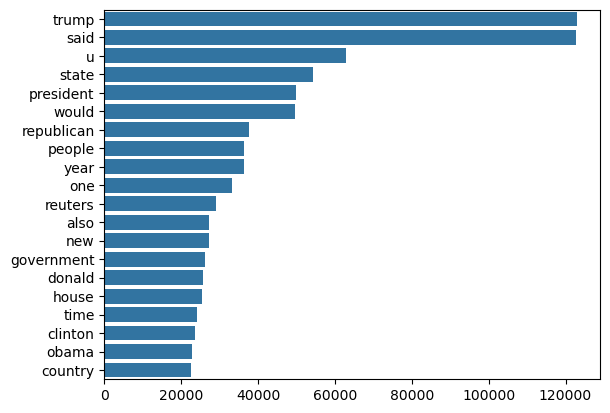

In [ ]:
from collections import Counter
import seaborn as sns

words = " ".join(data1['text']).split()
freq = Counter(words).most_common(20)
sns.barplot(x=[f[1] for f in freq], y=[f[0] for f in freq])
plt.show()

### Train-Test Splitting

In [19]:
X=data1[['title','text']]
y=data1['label']

In [20]:
from sklearn.model_selection import train_test_split

In [21]:
xtr, xts, ytr, yts = train_test_split(
    X, y, train_size = 0.8, stratify = y, random_state = 2025)

### Representations

**TF-IDF**

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [23]:
# Combine title and text into a single column
xtr_combined = xtr["title"] + " " + xtr["text"]

# Now apply TF-IDF
vectorizer = TfidfVectorizer(
    analyzer="word", max_df=0.8, min_df=10, ngram_range=(1, 2), norm="l2"
)
vectorizer.fit(xtr_combined)


TfidfVectorizer(max_df=0.8, min_df=10, ngram_range=(1, 2))

In [24]:
xts_combined = xts["title"] + " " + xts["text"]

In [25]:
xtr_vec = vectorizer.transform(xtr_combined)
xts_vec = vectorizer.transform(xts_combined )

**Bag of Words**

In [26]:
from sklearn.feature_extraction.text import CountVectorizer

bow_vectorizer = CountVectorizer()
X_bow = bow_vectorizer.fit(xtr_combined)

In [27]:
X_bow_tr = bow_vectorizer.transform(xtr_combined)
X_bow_ts = bow_vectorizer.transform(xts_combined)

# **Classical Models**

In [28]:
from sklearn.metrics import classification_report
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

### **Logistic Regression**

Using Bag Of words

In [29]:
model1=LogisticRegression()
model1.fit(X_bow_tr, ytr)

LogisticRegression()

In [30]:
preds1 = model1.predict(X_bow_ts)
print(classification_report(yts, preds1))

              precision    recall  f1-score   support

        fake       0.99      1.00      1.00      4239
        true       1.00      0.99      0.99      3582

    accuracy                           1.00      7821
   macro avg       1.00      0.99      1.00      7821
weighted avg       1.00      1.00      1.00      7821



Using TF-IDF

In [31]:
model1.fit(xtr_vec, ytr)

LogisticRegression()

In [32]:
preds1 = model1.predict(xts_vec)
print(classification_report(yts, preds1))

              precision    recall  f1-score   support

        fake       0.98      0.99      0.99      4239
        true       0.99      0.98      0.99      3582

    accuracy                           0.99      7821
   macro avg       0.99      0.99      0.99      7821
weighted avg       0.99      0.99      0.99      7821



Text(0.5, 1.0, 'Confusion Matrix')

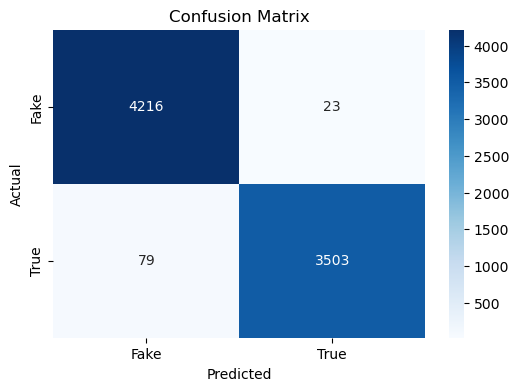

In [37]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(yts, preds1)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Fake', 'True'], yticklabels=['Fake', 'True'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

### **Naive Bayes**

Using Bag Of Words

In [38]:
model2 = MultinomialNB()
model2.fit(X_bow_tr, ytr)

MultinomialNB()

In [39]:
preds2 = model2.predict(X_bow_ts)
print(classification_report(yts, preds2))

              precision    recall  f1-score   support

        fake       0.96      0.95      0.96      4239
        true       0.95      0.95      0.95      3582

    accuracy                           0.95      7821
   macro avg       0.95      0.95      0.95      7821
weighted avg       0.95      0.95      0.95      7821



Using TF-IDF

In [40]:
model2.fit(xtr_vec, ytr)

MultinomialNB()

In [41]:
preds2 = model2.predict(xts_vec)
print(classification_report(yts, preds2))

              precision    recall  f1-score   support

        fake       0.96      0.96      0.96      4239
        true       0.95      0.95      0.95      3582

    accuracy                           0.96      7821
   macro avg       0.96      0.96      0.96      7821
weighted avg       0.96      0.96      0.96      7821



Text(0.5, 1.0, 'Confusion Matrix')

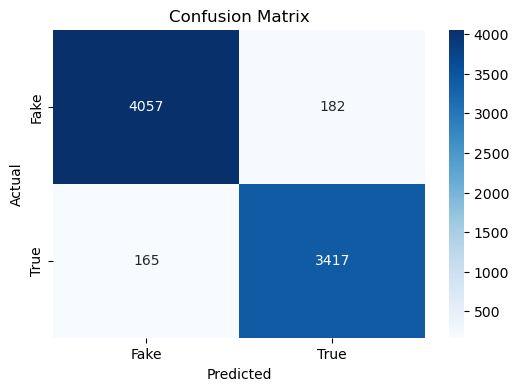

In [47]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(yts, preds2)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Fake', 'True'], yticklabels=['Fake', 'True'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

### **SVM**

Using Bag of Words

In [42]:
model3 = LinearSVC()
model3.fit(X_bow_tr, ytr)

LinearSVC()

In [43]:
preds3 = model3.predict(X_bow_ts)
print(classification_report(yts, preds3))

              precision    recall  f1-score   support

        fake       0.99      1.00      1.00      4239
        true       1.00      0.99      0.99      3582

    accuracy                           1.00      7821
   macro avg       1.00      1.00      1.00      7821
weighted avg       1.00      1.00      1.00      7821



Using TF-IDF

In [44]:
model3.fit(xtr_vec, ytr)

LinearSVC()

In [45]:
preds3 = model3.predict(xts_vec)
print(classification_report(yts, preds3))

              precision    recall  f1-score   support

        fake       0.99      1.00      1.00      4239
        true       1.00      0.99      0.99      3582

    accuracy                           0.99      7821
   macro avg       0.99      0.99      0.99      7821
weighted avg       0.99      0.99      0.99      7821



Text(0.5, 1.0, 'Confusion Matrix')

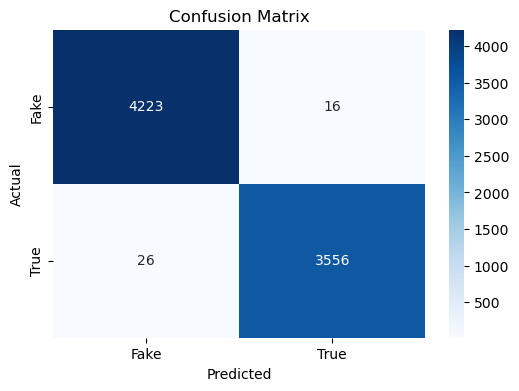

In [46]:
# Confusion Matrix
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(yts, preds3)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Fake', 'True'], yticklabels=['Fake', 'True'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')

# **Sequence Models**

### Function For Sequence Models

In [48]:
def clean_text_seq_models(text, stem=False, lem=False):
    # remove special characters and numbers
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    # remove unnecessary spaces
    text = re.sub(r"\s+", " ", text)
    # tokenize the text
    word_tokens = word_tokenize(text)
    # case folding
    word_tokens = [word.lower() for word in word_tokens]

    # lemmatization and/or stemming
    if lem:
        word_tokens = [lemmatizer.lemmatize(word) for word in word_tokens]
    if stem:
        word_tokens = [stemmer.stem(word) for word in word_tokens]

    text_clean = " ".join(word_tokens)
    return text_clean

In [49]:
data2["title"] = data2["title"].apply(lambda x: clean_text_seq_models(x, stem=False, lem=True))
data2["text"] = data2["text"].apply(lambda x: clean_text_seq_models(x, stem=False, lem=True))

In [ ]:
data2.sample(4)

,title,text,label
13304,are the nevertrumpers coming around jeb s son ...,will jeb kasich rubio and cruz continue with t...,fake
13239,unreal watch joe biden point out the guy who f...,are you kidding me this is the guy in charge o...,fake
5466,fox news expert will now be a prison expert fo...,he ha been tried he ha been convicted and now ...,fake
13234,obama release more dangerous terrorist to go c...,osama bin laden s bodyguard and other terroris...,fake


### Train-Test Split

In [50]:
X2=data2[['title','text']]
y2=data2['label']

In [51]:
x_train, x_test, y_train, y_test = train_test_split(
    X2, y2, train_size = 0.8, stratify = y2, random_state = 2025)

In [52]:
# Combine title and text into a single column
x_train_combined = x_train["title"] + " " + x_train["text"]
x_test_combined = x_test["title"] + " " + x_test["text"]

In [53]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)

### Tokenization

In [54]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [55]:
max_words = 20000  # same everywhere
tokenizer_sq = Tokenizer(num_words=max_words, oov_token="<OOV>")

In [56]:
tokenizer_sq.fit_on_texts(x_train_combined)

In [57]:
# Convert text to sequences
X_train_seq = tokenizer_sq.texts_to_sequences(x_train_combined)
X_test_seq = tokenizer_sq.texts_to_sequences(x_test_combined)

In [ ]:
X_train_seq[0]

[825,
 17553,
 21,
 2,
 588,
 470,
 3,
 14,
 8,
 3433,
 175,
 10,
 5577,
 5722,
 71,
 14,
 12,
 158,
 3,
 1223,
 19,
 3526,
 56,
 16,
 555,
 27,
 1545,
 2,
 120,
 14,
 21,
 48,
 7751,
 1944,
 733,
 1125,
 639,
 5577,
 5722,
 12,
 4,
 2154,
 2644,
 5,
 16355,
 1192,
 9,
 118,
 121,
 78,
 1347,
 3873,
 3,
 545,
 172,
 35,
 1051,
 4793,
 6814,
 733,
 1125,
 2902,
 3033,
 5,
 269,
 174,
 39,
 277,
 2778,
 178,
 110,
 204,
 799,
 35,
 3188,
 1927,
 5577,
 602,
 17,
 14202,
 1125,
 402,
 71,
 607,
 14,
 499,
 523,
 3,
 2998,
 4,
 3546,
 484,
 7,
 4,
 3471,
 278,
 62,
 47,
 8,
 4231,
 6,
 2552,
 10,
 2895,
 269,
 55,
 18,
 6258,
 3033,
 25,
 4,
 342,
 3098,
 35,
 15,
 72,
 71,
 607,
 14,
 499,
 523,
 149,
 438,
 1528,
 1668,
 3099,
 3985,
 2885,
 25,
 137,
 6,
 45,
 5107,
 14,
 8,
 89,
 65,
 440,
 13071,
 2081,
 3,
 1268,
 78,
 34,
 135,
 88,
 51,
 14484,
 20,
 19,
 175,
 6,
 178,
 14,
 1315,
 5722,
 324,
 2043,
 1927,
 1125,
 3660,
 6,
 4612,
 4,
 4,
 2089,
 5577,
 29,
 22,
 676,
 46,
 34,
 

### Padding

In [58]:
maxlen = 200
X_train_pad = pad_sequences(X_train_seq, maxlen=maxlen, padding='post')
X_test_pad = pad_sequences(X_test_seq, maxlen=maxlen, padding='post')

### Models

In [59]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, GRU, Dense

In [60]:
# Function to create RNN model
def create_rnn_model(max_words, embedding_dim, input_length):
    model = Sequential()
    model.add(Embedding(input_dim=max_words, output_dim=embedding_dim, input_length=input_length))
    model.add(SimpleRNN(units=128))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

    return model

# Function to create LSTM model
def create_lstm_model(max_words, embedding_dim, input_length):
    model = Sequential()
    model.add(Embedding(input_dim=max_words, output_dim=embedding_dim, input_length=input_length))
    model.add(LSTM(units=128))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

# Function to create GRU model
def create_gru_model(max_words, embedding_dim, input_length):
    model = Sequential()
    model.add(Embedding(input_dim=max_words, output_dim=embedding_dim, input_length=input_length))
    model.add(GRU(units=128))
    model.add(Dense(1, activation='sigmoid'))
    model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

In [61]:
# Define model parameters
max_words = 20000
embedding_dim = 128
input_length = 750
epochs = 8
batch_size = 64

### **RNN**

In [ ]:
# Train RNN model
rnn_model = create_rnn_model(max_words, embedding_dim, input_length)
print("Training RNN model...")
rnn_history = rnn_model.fit(X_train_pad, y_train, epochs=epochs, batch_size=batch_size, validation_split=0.2)
print(rnn_model.summary())

Training RNN model...
Epoch 1/8


c:\Users\somys\Downloads\anaconda\Lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


392/392 ━━━━━━━━━━━━━━━━━━━━ 47s 114ms/step - accuracy: 0.8512 - loss: 0.3439 - val_accuracy: 0.8798 - val_loss: 0.2876
Epoch 2/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 81s 111ms/step - accuracy: 0.8869 - loss: 0.2496 - val_accuracy: 0.7938 - val_loss: 0.3881
Epoch 3/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 47s 22ms/step - accuracy: 0.9011 - loss: 0.2259 - val_accuracy: 0.9386 - val_loss: 0.1879
Epoch 4/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 9s 23ms/step - accuracy: 0.9193 - loss: 0.1818 - val_accuracy: 0.9008 - val_loss: 0.2350
Epoch 5/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.9192 - loss: 0.1774 - val_accuracy: 0.8852 - val_loss: 0.2678
Epoch 6/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.9040 - loss: 0.2081 - val_accuracy: 0.8857 - val_loss: 0.2635
Epoch 7/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - accuracy: 0.9077 - loss: 0.1991 - val_accuracy: 0.6104 - val_loss: 0.8732
Epoch 8/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - accuracy: 0.8789 - loss: 0.2779 - val_accuracy: 0.8

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,779,077 (29.67 MB)

 Trainable params: 2,593,025 (9.89 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,186,052 (19.78 MB)

None


In [ ]:
import numpy as np

# Get predictions (probabilities)
y_pred_probs1 = rnn_model.predict(X_test_pad)

# Convert probabilities to class labels (0/1)
y_pred1 = (y_pred_probs1 > 0.5).astype("int32").flatten()

print(classification_report(y_test, y_pred1, digits=4))

245/245 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
              precision    recall  f1-score   support

           0     0.9316    0.7527    0.8326      3582
           1     0.8202    0.9533    0.8817      4239

    accuracy                         0.8614      7821
   macro avg     0.8759    0.8530    0.8572      7821
weighted avg     0.8712    0.8614    0.8592      7821



### **LSTM**

In [ ]:
# # Train LSTM model
lstm_model = create_lstm_model(max_words, embedding_dim, input_length)
print("Training LSTM model...")
lstm_history = lstm_model.fit(X_train_pad, y_train, epochs=epochs, batch_size=batch_size, validation_split=0.2)
print(lstm_model.summary())

Training LSTM model...
Epoch 1/8


c:\Users\somys\Downloads\anaconda\Lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


392/392 ━━━━━━━━━━━━━━━━━━━━ 36s 88ms/step - accuracy: 0.9206 - loss: 0.2367 - val_accuracy: 0.9444 - val_loss: 0.1538
Epoch 2/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 33s 84ms/step - accuracy: 0.9480 - loss: 0.1596 - val_accuracy: 0.9316 - val_loss: 0.1765
Epoch 3/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 33s 85ms/step - accuracy: 0.9447 - loss: 0.1528 - val_accuracy: 0.9519 - val_loss: 0.1247
Epoch 4/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 33s 85ms/step - accuracy: 0.9740 - loss: 0.0794 - val_accuracy: 0.9636 - val_loss: 0.1104
Epoch 5/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 34s 86ms/step - accuracy: 0.9782 - loss: 0.0710 - val_accuracy: 0.9661 - val_loss: 0.1081
Epoch 6/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 34s 86ms/step - accuracy: 0.9908 - loss: 0.0311 - val_accuracy: 0.9708 - val_loss: 0.1015
Epoch 7/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 33s 83ms/step - accuracy: 0.9940 - loss: 0.0202 - val_accuracy: 0.9752 - val_loss: 0.0947
Epoch 8/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 33s 85ms/step - accuracy: 0.9976 - loss: 0.0092 - val_accuracy: 0.97

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 200, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,075,141 (30.80 MB)

 Trainable params: 2,691,713 (10.27 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,383,428 (20.54 MB)

None


In [ ]:
# Get predictions (probabilities)
y_pred_probs2 = lstm_model.predict(X_test_pad)

# Convert probabilities to class labels (0/1)
y_pred2 = (y_pred_probs2 > 0.5).astype("int32").flatten()

print(classification_report(y_test, y_pred2, digits=4))

245/245 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step
              precision    recall  f1-score   support

           0     0.9786    0.9707    0.9746      3582
           1     0.9754    0.9821    0.9787      4239

    accuracy                         0.9769      7821
   macro avg     0.9770    0.9764    0.9767      7821
weighted avg     0.9769    0.9769    0.9768      7821



### **GRU**

In [62]:
# Train GRU model
gru_model = create_gru_model(max_words, embedding_dim, input_length)
print("Training GRU model...")
gru_history = gru_model.fit(X_train_pad, y_train, epochs=epochs, batch_size=batch_size, validation_split=0.2)
print(gru_model.summary())

c:\Users\somys\anaconda3\Lib\site-packages\keras\src\layers\core\embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Training GRU model...
Epoch 1/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 149s 373ms/step - accuracy: 0.8638 - loss: 0.3834 - val_accuracy: 0.9519 - val_loss: 0.1561
Epoch 2/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 102s 259ms/step - accuracy: 0.9578 - loss: 0.1317 - val_accuracy: 0.8776 - val_loss: 0.2769
Epoch 3/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 31s 80ms/step - accuracy: 0.9414 - loss: 0.1474 - val_accuracy: 0.9537 - val_loss: 0.1456
Epoch 4/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 41s 105ms/step - accuracy: 0.9388 - loss: 0.1693 - val_accuracy: 0.9741 - val_loss: 0.0757
Epoch 5/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - accuracy: 0.9928 - loss: 0.0216 - val_accuracy: 0.9768 - val_loss: 0.0735
Epoch 6/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 43s 109ms/step - accuracy: 0.9979 - loss: 0.0086 - val_accuracy: 0.9792 - val_loss: 0.0695
Epoch 7/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 38s 97ms/step - accuracy: 0.9996 - loss: 0.0033 - val_accuracy: 0.9816 - val_loss: 0.0767
Epoch 8/8
392/392 ━━━━━━━━━━━━━━━━━━━━ 35s 90ms/step - accuracy: 0.9

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 128)            │        99,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,977,605 (30.43 MB)

 Trainable params: 2,659,201 (10.14 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,318,404 (20.29 MB)

None


In [64]:
# Get predictions (probabilities)
y_pred_probs3 = gru_model.predict(X_test_pad)

# Convert probabilities to class labels (0/1)
y_pred3 = (y_pred_probs3 > 0.5).astype("int32").flatten()

print(classification_report(y_test, y_pred3, digits=4))

245/245 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step
              precision    recall  f1-score   support

           0     0.9755    0.9866    0.9810      4239
           1     0.9839    0.9707    0.9772      3582

    accuracy                         0.9793      7821
   macro avg     0.9797    0.9786    0.9791      7821
weighted avg     0.9793    0.9793    0.9793      7821



ROC Curves

In [ ]:
# Function to plot training history
def plot_history(history, model_name):
    # Plotting accuracy
    plt.figure(figsize=(12, 4))

    # Accuracy plot
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title(f'{model_name} Accuracy')
    plt.xlabel('Epochs')
    plt.ylabel('Accuracy')
    plt.legend()

    # Loss plot
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'{model_name} Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()

    plt.show()


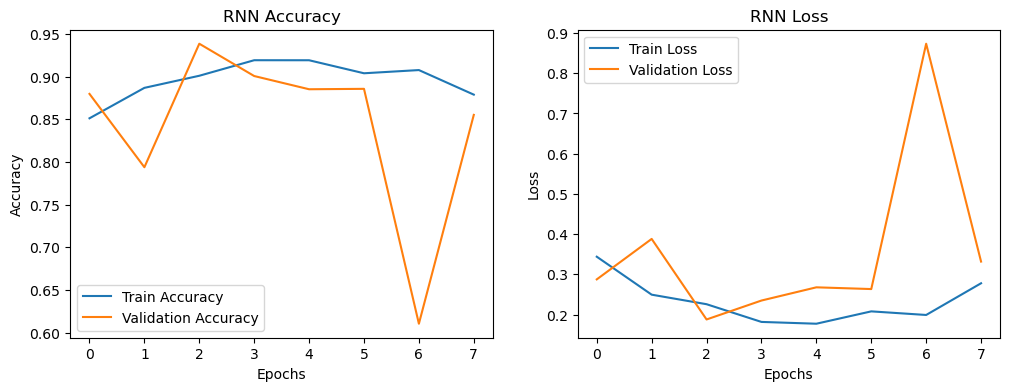

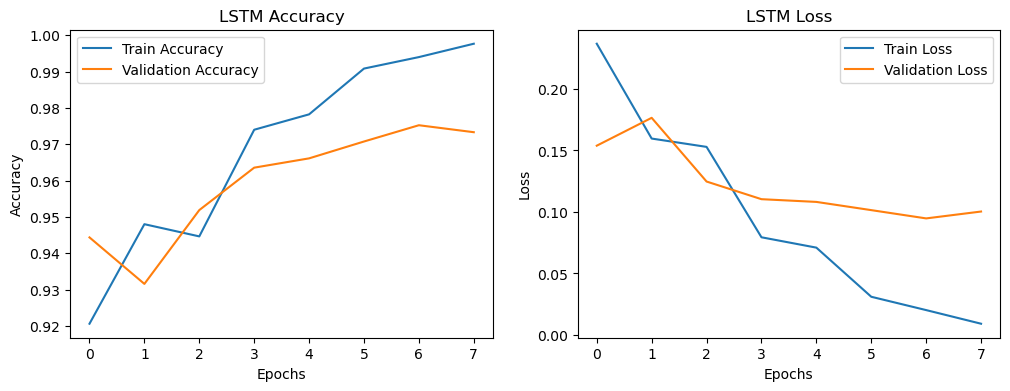

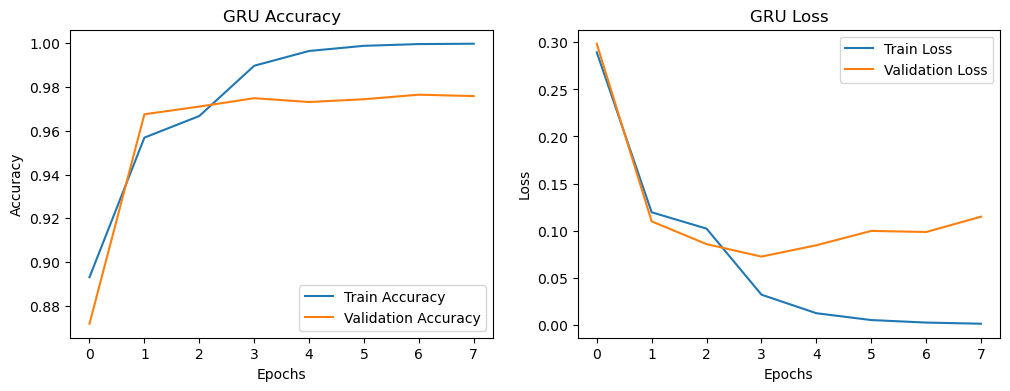

In [ ]:
# Plotting the training history for each model
plot_history(rnn_history, 'RNN')
plot_history(lstm_history, 'LSTM')
plot_history(gru_history, 'GRU')



# **Use Pretrained Embeddings**

### **1 - GloVe**

Load GloVe into a dictionary

In [ ]:
# Path to GloVe file
glove_path = "glove.6B.50d.txt"

# Load embeddings into a dictionary
embeddings_index = {}
with open(glove_path, encoding="utf-8") as f:
    for line in f:
        values = line.split()
        word = values[0]
        coeffs = np.asarray(values[1:], dtype="float32")
        embeddings_index[word] = coeffs

print(f"Loaded {len(embeddings_index)} word vectors.")


Loaded 400000 word vectors.


In [ ]:
embedding_dim = 50
word_index = tokenizer_sq.word_index  # from the earlier tokenizer

# Initialize embedding matrix
embedding_matrix = np.zeros((max_words, embedding_dim))

for word, i in word_index.items():
    if i < max_words:
        embedding_vector = embeddings_index.get(word)
        if embedding_vector is not None:
            embedding_matrix[i] = embedding_vector


In [ ]:
from tensorflow.keras.layers import Embedding

embedding_layer = Embedding(
    input_dim=max_words,
    output_dim=embedding_dim,
    weights=[embedding_matrix],
    input_length=input_length,
    trainable=False   # keep pretrained fixed (set True if you want fine-tuning)
)


c:\Users\somys\Downloads\anaconda\Lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:

model = Sequential()
model.add(embedding_layer)  # use pretrained embeddings
model.add(GRU(128, dropout=0.2, recurrent_dropout=0.2))
model.add(Dense(1, activation="sigmoid"))

model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_3 (GRU)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,000,000 (3.81 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 1,000,000 (3.81 MB)

In [ ]:
history = model.fit(X_train_pad, y_train,
                    validation_split=0.2,
                    epochs=5,
                    batch_size=64)


Epoch 1/5
392/392 ━━━━━━━━━━━━━━━━━━━━ 34s 81ms/step - accuracy: 0.8752 - loss: 0.3058 - val_accuracy: 0.9036 - val_loss: 0.2344
Epoch 2/5
392/392 ━━━━━━━━━━━━━━━━━━━━ 31s 80ms/step - accuracy: 0.9037 - loss: 0.2328 - val_accuracy: 0.8681 - val_loss: 0.2815
Epoch 3/5
392/392 ━━━━━━━━━━━━━━━━━━━━ 35s 89ms/step - accuracy: 0.9320 - loss: 0.1775 - val_accuracy: 0.9602 - val_loss: 0.1171
Epoch 4/5
392/392 ━━━━━━━━━━━━━━━━━━━━ 35s 90ms/step - accuracy: 0.9549 - loss: 0.1260 - val_accuracy: 0.9663 - val_loss: 0.0995
Epoch 5/5
392/392 ━━━━━━━━━━━━━━━━━━━━ 35s 90ms/step - accuracy: 0.9634 - loss: 0.1038 - val_accuracy: 0.9711 - val_loss: 0.0856


In [ ]:
loss1, acc1 = model.evaluate(X_test_pad, y_test)
print(f"GRU + GloVe Accuracy: {acc1:.4f}")

245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9729 - loss: 0.0751
GRU + GloVe Accuracy: 0.9729


### **2 - Word2Vec**

In [ ]:
from gensim.models import Word2Vec

# Prepare your tokenized texts
sentences = [text.split() for text in x_train_combined]

# Train Word2Vec on your corpus
w2v_model = Word2Vec(sentences, vector_size=100, window=5, min_count=2, workers=4)

In [ ]:
# Build embedding matrix
embedding_dim = 100
word_index = tokenizer_sq.word_index
embedding_matrix_w2v = np.zeros((max_words, embedding_dim))

for word, i in word_index.items():
    if i < max_words:
        if word in w2v_model.wv:
            embedding_matrix_w2v[i] = w2v_model.wv[word]

In [ ]:
gru_model_w2v = Sequential([
    Embedding(input_dim=max_words,
              output_dim=embedding_dim,
              weights=[embedding_matrix_w2v],
              input_length=maxlen,
              trainable=False),
    GRU(128, return_sequences=False),
    Dense(1, activation='sigmoid')
])

gru_model_w2v.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
gru_model_w2v.summary()

c:\Users\somys\Downloads\anaconda\Lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │     2,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,000,000 (7.63 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,000,000 (7.63 MB)

In [ ]:
gru_model_w2v.fit(X_train_pad, y_train, validation_split=0.2, epochs=5, batch_size=64, verbose=1)

Epoch 1/5
392/392 ━━━━━━━━━━━━━━━━━━━━ 40s 99ms/step - accuracy: 0.9398 - loss: 0.1712 - val_accuracy: 0.9626 - val_loss: 0.1100
Epoch 2/5
392/392 ━━━━━━━━━━━━━━━━━━━━ 26s 67ms/step - accuracy: 0.9771 - loss: 0.0730 - val_accuracy: 0.9749 - val_loss: 0.0840
Epoch 3/5
392/392 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - accuracy: 0.9863 - loss: 0.0450 - val_accuracy: 0.9826 - val_loss: 0.0588
Epoch 4/5
392/392 ━━━━━━━━━━━━━━━━━━━━ 28s 70ms/step - accuracy: 0.9916 - loss: 0.0284 - val_accuracy: 0.9802 - val_loss: 0.0675
Epoch 5/5
392/392 ━━━━━━━━━━━━━━━━━━━━ 28s 70ms/step - accuracy: 0.9947 - loss: 0.0182 - val_accuracy: 0.9850 - val_loss: 0.0493
245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9868 - loss: 0.0435
GRU + Word2Vec Accuracy: 0.9868


In [ ]:
loss2, acc2 = gru_model_w2v.evaluate(X_test_pad, y_test)
print(f"GRU + Word2Vec Accuracy: {acc2:.4f}")

245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9868 - loss: 0.0435
GRU + Word2Vec Accuracy: 0.9868


### **3 - FastText**

In [ ]:
from gensim.models import FastText
# Train FastText on your dataset
ft_model = FastText(sentences, vector_size=100, window=5, min_count=2, workers=4)

In [ ]:
# Build embedding matrix
embedding_dim = 100
embedding_matrix_ft = np.zeros((max_words, embedding_dim))

for word, i in word_index.items():
    if i < max_words:
        if word in ft_model.wv:
            embedding_matrix_ft[i] = ft_model.wv[word]

In [ ]:
gru_model_ft = Sequential([
    Embedding(input_dim=max_words,
              output_dim=embedding_dim,
              weights=[embedding_matrix_ft],
              input_length=maxlen,
              trainable=False),
    GRU(128, return_sequences=False),
    Dense(1, activation='sigmoid')
])

gru_model_ft.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
gru_model_ft.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ ?                      │     2,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,000,000 (7.63 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,000,000 (7.63 MB)

In [ ]:
gru_model_ft.fit(X_train_pad, y_train, validation_split=0.2, epochs=5, batch_size=64, verbose=1)


Epoch 1/5
392/392 ━━━━━━━━━━━━━━━━━━━━ 28s 67ms/step - accuracy: 0.9179 - loss: 0.2205 - val_accuracy: 0.9230 - val_loss: 0.2202
Epoch 2/5
392/392 ━━━━━━━━━━━━━━━━━━━━ 26s 66ms/step - accuracy: 0.9540 - loss: 0.1402 - val_accuracy: 0.9565 - val_loss: 0.1451
Epoch 3/5
392/392 ━━━━━━━━━━━━━━━━━━━━ 27s 70ms/step - accuracy: 0.9508 - loss: 0.1420 - val_accuracy: 0.9445 - val_loss: 0.1601
Epoch 4/5
392/392 ━━━━━━━━━━━━━━━━━━━━ 27s 70ms/step - accuracy: 0.9674 - loss: 0.1002 - val_accuracy: 0.9637 - val_loss: 0.1131
Epoch 5/5
392/392 ━━━━━━━━━━━━━━━━━━━━ 74s 188ms/step - accuracy: 0.9800 - loss: 0.0661 - val_accuracy: 0.9637 - val_loss: 0.1106


In [ ]:
loss3, acc3 = gru_model_ft.evaluate(X_test_pad, y_test)
print(f"GRU + FastText Accuracy: {acc3:.4f}")

245/245 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.9670 - loss: 0.1006
GRU + FastText Accuracy: 0.9670


# **Transformers & Modern NLP**

In [ ]:
! pip install transformers datasets

  Using cached datasets-4.0.0-py3-none-any.whl.metadata (19 kB)
  Using cached huggingface_hub-0.34.4-py3-none-any.whl.metadata (14 kB)
  Using cached tokenizers-0.21.4-cp39-abi3-win_amd64.whl.metadata (6.9 kB)
  Using cached safetensors-0.6.2-cp38-abi3-win_amd64.whl.metadata (4.1 kB)
  Using cached xxhash-3.5.0-cp312-cp312-win_amd64.whl.metadata (13 kB)
  Using cached multiprocess-0.70.16-py312-none-any.whl.metadata (7.2 kB)
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.3 MB ? eta -:--:--
   -------

In [ ]:
! pip install torch

In [19]:
import os
os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "600"  # 10 minutes

In [20]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from transformers import BertTokenizer, BertForSequenceClassification
from torch.optim import AdamW
from sklearn.metrics import accuracy_score, classification_report
from tqdm import tqdm

1. Load tokenizer & model

In [21]:
MODEL_NAME = "bert-base-uncased"  # standard BERT
tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

2. Create Dataset class

In [22]:
class FakeNewsDataset(Dataset):
    def __init__(self, texts, labels, tokenizer, max_len=256):
        self.texts = texts
        self.labels = labels
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        text = str(self.texts.iloc[idx] if hasattr(self.texts, "iloc") else self.texts[idx])
        label = int(self.labels[idx])

        encoding = self.tokenizer.encode_plus(
            text,
            add_special_tokens=True,
            max_length=self.max_len,
            truncation=True,
            padding="max_length",
            return_attention_mask=True,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].flatten(),
            "attention_mask": encoding["attention_mask"].flatten(),
            "labels": torch.tensor(label, dtype=torch.long)
        }


3. Create DataLoaders

In [23]:
BATCH_SIZE = 16

train_dataset = FakeNewsDataset(x_train_combined, y_train, tokenizer)
test_dataset = FakeNewsDataset(x_test_combined, y_test, tokenizer)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

4. Load Model

In [24]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = BertForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)
model = model.to(device)

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


5. Optimizer & Loss

In [25]:
optimizer = AdamW(model.parameters(), lr=2e-5)
criterion = nn.CrossEntropyLoss()

6. Training Loop

In [26]:
EPOCHS = 2

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for batch in tqdm(train_loader, desc=f"Training Epoch {epoch+1}"):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_train_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch+1}/{EPOCHS} - Training Loss: {avg_train_loss:.4f}")

Training Epoch 1: 100%|██████████| 1956/1956 [26:06<00:00,  1.25it/s]


Epoch 1/2 - Training Loss: 0.0260


Training Epoch 2: 100%|██████████| 1956/1956 [26:05<00:00,  1.25it/s]

Epoch 2/2 - Training Loss: 0.0050


7. Evaluation

In [27]:
model.eval()
y_true, y_pred = [], []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Evaluating"):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = model(input_ids, attention_mask=attention_mask)
        preds = torch.argmax(outputs.logits, dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(preds.cpu().numpy())

print("Accuracy:", accuracy_score(y_true, y_pred))
print("\nClassification Report:\n", classification_report(y_true, y_pred, digits=4))


Evaluating: 100%|██████████| 489/489 [02:35<00:00,  3.14it/s]

Accuracy: 0.998849252013809

Classification Report:
               precision    recall  f1-score   support

           0     0.9980    0.9994    0.9987      3582
           1     0.9995    0.9983    0.9989      4239

    accuracy                         0.9988      7821
   macro avg     0.9988    0.9989    0.9988      7821
weighted avg     0.9989    0.9988    0.9988      7821



In [28]:
save_path = "saved_fakenews_model"

model.save_pretrained(save_path)
tokenizer.save_pretrained(save_path)

('C:\\\\Users\\\\somys\\\\Downloads\\\\Final_Project_NLP\\\\saved_fakenews_model/tokenizer_config.json',
 'C:\\\\Users\\\\somys\\\\Downloads\\\\Final_Project_NLP\\\\saved_fakenews_model/special_tokens_map.json',
 'C:\\\\Users\\\\somys\\\\Downloads\\\\Final_Project_NLP\\\\saved_fakenews_model/vocab.txt',
 'C:\\\\Users\\\\somys\\\\Downloads\\\\Final_Project_NLP\\\\saved_fakenews_model/added_tokens.json')

In [29]:
from transformers import BertTokenizer, BertForSequenceClassification
import torch

# Load back the fine-tuned model
tokenizer = BertTokenizer.from_pretrained(save_path)
model = BertForSequenceClassification.from_pretrained(save_path)
model.eval()


BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e

In [30]:
def predict_fake_news(text):
    inputs = tokenizer(text, return_tensors="pt", padding=True, truncation=True, max_length=256)
    with torch.no_grad():
        outputs = model(**inputs)
        prediction = torch.argmax(outputs.logits, dim=1).item()

    if prediction == 1:
        return "Real"
    else:
        return "Fake"

In [31]:
print(predict_fake_news("The following statements were posted to the verified Twitter accounts of U.S. President Donald Trump, @realDonaldTrump and @POTUS.  The opinions expressed are his own. Reuters has not edited the statements or confirmed their accuracy.  @realDonaldTrump : - Our big and very popular Tax Cut and Reform Bill has taken on an unexpected new source of “love” - that is big companies and corporations showering their workers with bonuses. This is a phenomenon that nobody even thought of, and now it is the rage. Merry Christmas! [0747 EST] - At some point, and for the good of the country, I predict we will start working with the Democrats in a Bipartisan fashion. Infrastructure would be a perfect place to start. After having foolishly spent $7 trillion in the Middle East, it is time to start rebuilding our country! [0805 EST] - “The President has accomplished some absolutely historic things during this past year.” Thank you Charlie Kirk of Turning Points USA. Sadly, the Fake Mainstream Media will NEVER talk about our accomplishments in their end of year reviews. We are compiling a long & beautiful list. [0917 EST] - With all my Administration has done on Legislative Approvals (broke Harry Truman’s Record), Regulation Cutting, Judicial Appointments, Building Military, VA, TAX CUTS & REFORM, Record Economy/Stock Market and so much more, I am sure great credit will be given by mainstream news? [1004 EST] - Will be signing the biggest ever Tax Cut and Reform Bill in 30 minutes in Oval Office. Will also be signing a much needed 4 billion dollar missile defense bill. [1007 EST] -- Source link: (bit.ly/2jBh4LU) (bit.ly/2jpEXYR)  "))
print(predict_fake_news("The number of cases of cops brutalizing and killing people of color seems to see no end. Now, we have another case that needs to be shared far and wide. An Alabama woman by the name of Angela Williams shared a graphic photo of her son, lying in a hospital bed with a beaten and fractured face, on Facebook. It needs to be shared far and wide, because this is unacceptable.It is unclear why Williams  son was in police custody or what sort of altercation resulted in his arrest, but when you see the photo you will realize that these details matter not. Cops are not supposed to beat and brutalize those in their custody. In the post you are about to see, Ms. Williams expresses her hope that the cops had their body cameras on while they were beating her son, but I think we all know that there will be some kind of convenient  malfunction  to explain away the lack of existence of dash or body camera footage of what was clearly a brutal beating. Hell, it could even be described as attempted murder. Something tells me that this young man will never be the same. Without further ado, here is what Troy, Alabama s finest decided was appropriate treatment of Angela Williams  son:No matter what the perceived crime of this young man might be, this is completely unacceptable. The cops who did this need to rot in jail for a long, long time   but what you wanna bet they get a paid vacation while the force  investigates  itself, only to have the officers returned to duty posthaste?This, folks, is why we say BLACK LIVES MATTER. No way in hell would this have happened if Angela Williams  son had been white. Please share far and wide, and stay tuned to Addicting Info for further updates.Featured image via David McNew/Stringer/Getty Images"))


Real
Fake


# **Sentiment Analysis**

In [32]:
import torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch.nn.functional as F

In [33]:
# 1. Load pretrained model
MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment"
tokenizer2 = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME)

config.json:   0%|          | 0.00/747 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/499M [00:00<?, ?B/s]

In [34]:
# Label mapping (from model card)
labels = ["Negative", "Neutral", "Positive"]

In [35]:
# 2. Prediction function
def predict_sentiment(text, model=model, tokenizer=tokenizer2):
    # Tokenize
    inputs = tokenizer2(text, return_tensors="pt", truncation=True, padding=True)

    # Forward pass
    with torch.no_grad():
        outputs = model(**inputs)
        probs = F.softmax(outputs.logits, dim=1).squeeze()

    # Get predicted class
    pred_idx = torch.argmax(probs).item()
    sentiment = labels[pred_idx]
    confidence = probs[pred_idx].item() * 100

    return f"Sentiment: {sentiment} ({confidence:.2f}% confidence)"

In [36]:
# Example usage
print(predict_sentiment("I love this new phone!"))
print(predict_sentiment("The Movie is mid."))
print(predict_sentiment("This is the worst experience ever!!"))

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


Sentiment: Positive (99.23% confidence)
Sentiment: Neutral (57.51% confidence)
Sentiment: Negative (97.97% confidence)


### **For API** 

In [ ]:
!pip install pyngrok
from pyngrok import ngrok
public_url = ngrok.connect(8000)
print(public_url)

NgrokTunnel: "https://046845efd741.ngrok-free.app" -> "http://localhost:8000"
